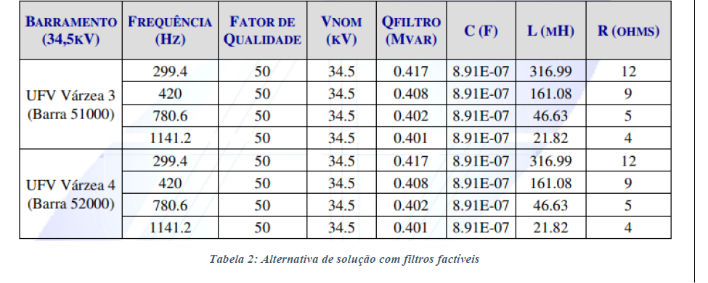

In [23]:
import numpy as np

In [24]:
def Z_filtro(h, w1, R, L, C):
    w = h * w1
    XL = w*L
    XC = 1/(w*C)
    Z = R + 1j*XL - 1j*XC
    return Z

In [25]:
R = np.array([12, 9, 5, 4])
L = 1e-3 * np.array([316.99, 161.08, 46.3, 21.82])
C = np.array([8.91e-7, 8.91e-7, 8.91e-7, 8.91e-7])
w1 = 2*np.pi*60
V1 = 34.5e3 / np.sqrt(3)
S_trafo = 45e6 # dúvida se é essa mesmo!
V_trafo = 34.5e3
I_trafo = S_trafo/(np.sqrt(3)*V_trafo)
Z1_trafo_pu = 14/100
I0_filtro_pu = np.array([0.46/100, 0.42/100, 0.28/100, 0.22/100])

In [26]:
w0 = 1 / np.sqrt(L*C)
h0 = w0 / w1
print(f"Harmônico a filtrar = {np.round(np.abs(h0), 3)}")

Harmônico a filtrar = [ 4.991  7.002 13.06  19.024]


In [27]:
XL1 = w1*L
XC1 = 1/(w1*C)
Z1 = R + 1j*XL1 - 1j*XC1
I1 = V1 / Z1
VC1 = -1j*XC1*I1
VL1 =  1j*XL1*I1
VR1 =  R*I1
print(f"Corrente Ampères @60Hz do filtro = {np.round(np.abs(I1), 2)}")
print(f"Tensao Volts @60Hz no capacitor = {np.round(np.abs(VC1), 1)}")
print(f"Tensao % @60Hz no capacitor = {100*np.round(np.abs(VC1)/V1, 6)}")

Corrente Ampères @60Hz do filtro = [6.97 6.83 6.73 6.71]
Tensao Volts @60Hz no capacitor = [20751.4 20333.2 20036.  19973.8]
Tensao % @60Hz no capacitor = [104.181  102.0818 100.5896 100.277 ]


In [28]:
SC1 = 3 * VC1 * np.conj(I1)
SL1 = 3 * VL1 * np.conj(I1)
SR1 = 3 * VR1 * np.conj(I1)
FQ = w0 * L / R
print(f"Potência MVAr no @60Hz no capacitor = {np.round(np.imag(SC1)/1e6, 3)}")
print(f"Fator de Qualidade do Filtro/Indutor = {np.round(FQ, 3)}")

Potência MVAr no @60Hz no capacitor = [-0.434 -0.417 -0.405 -0.402]
Fator de Qualidade do Filtro/Indutor = [49.705 47.243 45.591 39.123]


In [29]:
Z1_trafo = V_trafo**2/S_trafo* Z1_trafo_pu # V1 é tensão de fase, cuidar
Z0_trafo = 1j*h0 * Z1_trafo
Z0_filtro = Z_filtro(h0, w1, R, L, C)
print(f"Filtros   sintonizados    em h0 ==> {np.round(h0, 3)}")
print(f"Impedância Ohms do TRAFO  em h0 ==> {np.round(np.abs(Z0_trafo), 3)}")
print(f"Impedância Ohms do FILTRO em h0 ==> {np.round(np.abs(Z0_filtro), 3)}")

Filtros   sintonizados    em h0 ==> [ 4.991  7.002 13.06  19.024]
Impedância Ohms do TRAFO  em h0 ==> [18.483 25.928 48.361 70.446]
Impedância Ohms do FILTRO em h0 ==> [12.  9.  5.  4.]


In [30]:
I0_inversor = I_trafo * I0_filtro_pu
# I0_filtro = I0_inversor * Z0_trafo / (Z0_trafo + Z0_filtro)
I_total_filtro = np.sqrt(np.abs(I1)**2 + I0_inversor**2)
print(f"Corrente TOTAL Ampères do filtro ==> {np.round(np.abs(I_total_filtro), 3)}")
print(f"Corrente TOTAL %       do filtro ==> {np.round(100*np.abs(I_total_filtro/I1), 1)}")
print(f"Filtros   sintonizados     em h0 ==> {np.round(h0, 3)}")

Corrente TOTAL Ampères do filtro ==> [7.784 7.527 7.053 6.911]
Corrente TOTAL %       do filtro ==> [111.7 110.2 104.8 103. ]
Filtros   sintonizados     em h0 ==> [ 4.991  7.002 13.06  19.024]


In [31]:
import pandas as pd

data = {
    'Sintonia': np.round(h0, 1),
    'FQ': np.round(FQ,1),
    'MVAr': np.round(np.imag(SC1)/1e6, 3),
    'uF': C/1e-6,
    'mH': L/1e-3,
    'Ohms': R,
    'Ic (A)': np.round(np.abs(I_total_filtro), 3),
    'Ic (%)': np.round(np.abs(I_total_filtro/I1), 3)
}

df = pd.DataFrame(data)
df


,Sintonia,FQ,MVAr,uF,mH,Ohms,Ic (A),Ic (%)
0,5.0,49.7,-0.434,0.891,316.99,12,7.784,1.117
1,7.0,47.2,-0.417,0.891,161.08,9,7.527,1.102
2,13.1,45.6,-0.405,0.891,46.30,5,7.053,1.048
3,19.0,39.1,-0.402,0.891,21.82,4,6.911,1.030


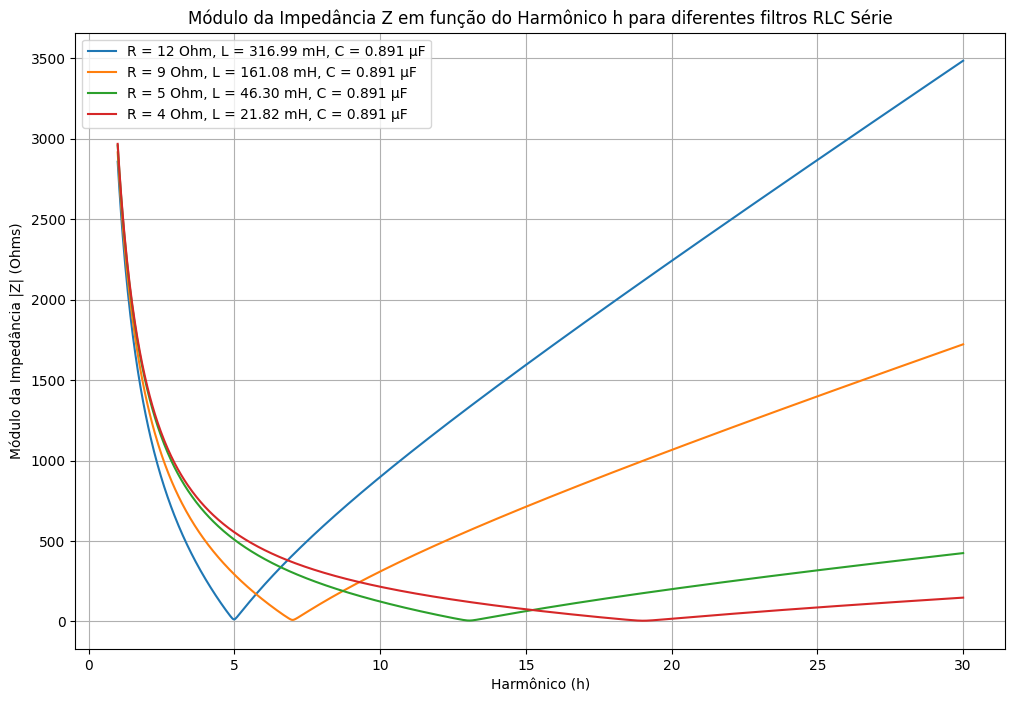

In [32]:
import matplotlib.pyplot as plt

# Definição das constantes

# Definição do intervalo de harmônicos
h = np.linspace(1, 30, 1000)
w = 2 * np.pi * 60 * h

# Cálculo do módulo da impedância Z para cada valor de R, L, C
Z = [np.sqrt(R[i]**2 + (w*L[i] - 1/(w*C[i]))**2) for i in range(len(R))]

# Plotando o gráfico
plt.figure(figsize=(12, 8))
for i in range(len(R)):
    plt.plot(h, Z[i], label=f'R = {R[i]} Ohm, L = {L[i]*1e3:.2f} mH, C = {C[i]*1e6:.3f} \u03BCF')

plt.xlabel('Harmônico (h)')
plt.ylabel('Módulo da Impedância |Z| (Ohms)')
plt.title('Módulo da Impedância Z em função do Harmônico h para diferentes filtros RLC Série')
plt.legend()
plt.grid(True)
plt.show()
